In [1]:
from google.colab import files
uploaded = files.upload()

Saving loan_default.csv to loan_default.csv


In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
df = pd.read_csv('loan_default.csv')
print(df.shape); df.info(); print(df.head(10))

(1012, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        1012 non-null   object 
 1   age                1012 non-null   int64  
 2   income             1012 non-null   float64
 3   loan_amount        1012 non-null   float64
 4   credit_score       1012 non-null   float64
 5   employment_years   1012 non-null   float64
 6   debt_to_income     1012 non-null   float64
 7   existing_loans     1012 non-null   int64  
 8   dependents         1012 non-null   int64  
 9   bank_balance       1012 non-null   float64
 10  interest_rate      1012 non-null   float64
 11  employment_type    1012 non-null   object 
 12  marital_status     1012 non-null   object 
 13  education          951 non-null    object 
 14  loan_purpose       1012 non-null   object 
 15  city_tier          1012 non-null   object 
 16  previous_defa

The dataset has 1012 rows and 18 columns. Numeric columns (11): age, income, loan_amount, credit_score, employment_years, debt_to_income, existing_loans, dependents, bank_balance, interest_rate, previous_defaults. Categorical (text) columns: employment_type, marital_status, education, loan_purpose, city_tier, plus the target loan_default. customer_id is just an identifier.

               age         income    loan_amount  credit_score  \
count  1012.000000    1012.000000    1012.000000   1012.000000   
mean     42.669960   54157.542490  246006.705534    651.821146   
std      13.986137   21295.031417  116654.104628     79.549937   
min     -52.000000  -74577.000000   20000.000000    411.000000   
25%      32.000000   40859.000000  169464.500000    596.750000   
50%      43.000000   53837.500000  242872.000000    651.500000   
75%      54.000000   68032.750000  324349.500000    705.000000   
max      64.000000  111578.000000  667635.000000    900.000000   

       employment_years  debt_to_income  existing_loans   dependents  \
count       1012.000000     1012.000000     1012.000000  1012.000000   
mean           9.994763        0.368216        0.996047     1.936759   
std            7.718507        0.154261        0.979505     1.390213   
min            0.000000        0.020000        0.000000     0.000000   
25%            3.875000        0.263000      

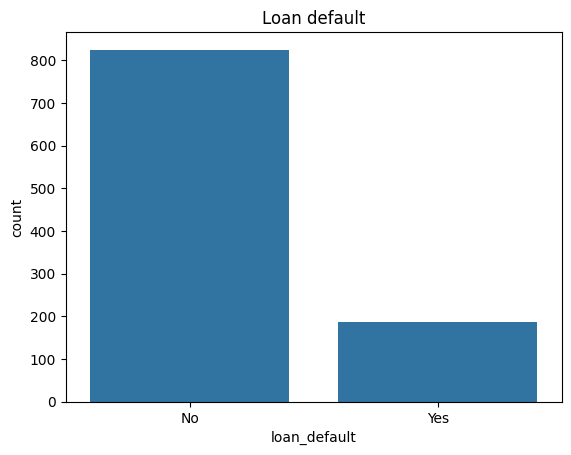

loan_default
No     0.815217
Yes    0.184783
Name: proportion, dtype: float64


In [3]:
print(df.describe())
for c in df.select_dtypes('object').columns.drop('customer_id'):
    print(df[c].value_counts(dropna=False), '\n')
sns.countplot(x='loan_default', data=df); plt.title('Loan default'); plt.show()
print(df['loan_default'].value_counts(normalize=True))

The target is **imbalanced**: about 81.5% No (825) vs 18.5% Yes (187). This matters because a model can reach ~81% accuracy by always predicting “No” while catching no defaulters, so accuracy alone is misleading and recall / F1 / ROC-AUC must be checked.

In [4]:
print(df.isnull().sum())
df['education'] = df['education'].fillna(df['education'].mode()[0])
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates()
print('Negative ages:', (df['age']<0).sum(), '| Negative incomes:', (df['income']<0).sum())
df.loc[df['age']<0,'age'] = df['age'].abs()
df.loc[df['income']<0,'income'] = df['income'].abs()
df = df.drop_duplicates()
print('Duplicate customer_ids left:', df['customer_id'].duplicated().sum())
print('Shape after cleaning:', df.shape)
print(df[['age','income']].min())

customer_id           0
age                   0
income                0
loan_amount           0
credit_score          0
employment_years      0
debt_to_income        0
existing_loans        0
dependents            0
bank_balance          0
interest_rate         0
employment_type       0
marital_status        0
education            61
loan_purpose          0
city_tier             0
previous_defaults     0
loan_default          0
dtype: int64
Duplicate rows: 11
Negative ages: 5 | Negative incomes: 5
Duplicate customer_ids left: 0
Shape after cleaning: (1000, 18)
age          21.0
income    12000.0
dtype: float64


Only **education** had missing values (61). I filled them with the **most frequent value (mode)** because it is a categorical column, so a mean cannot be used, and this keeps all 61 rows instead of losing data. I also found **11 duplicate rows** (dropped) and **5 negative ages and 5 negative incomes**, which are impossible; they looked like sign typos (e.g., age −22 was a duplicate of age 22), so I converted them with abs(). After that one more duplicate appeared and was dropped, leaving **1000 rows**.

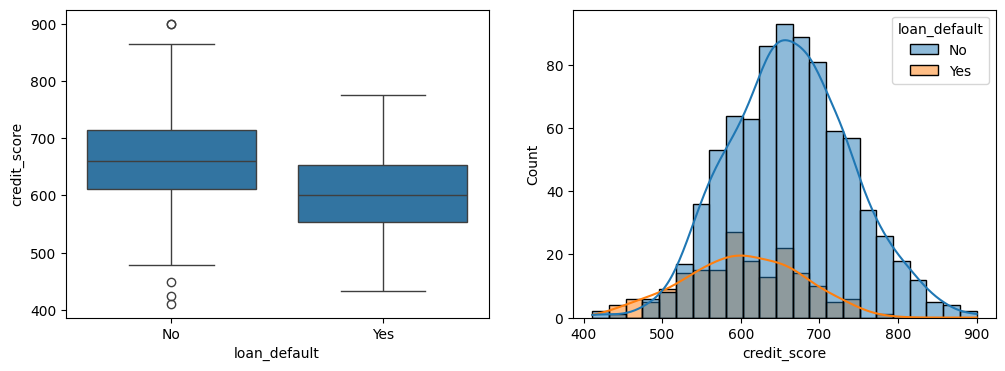

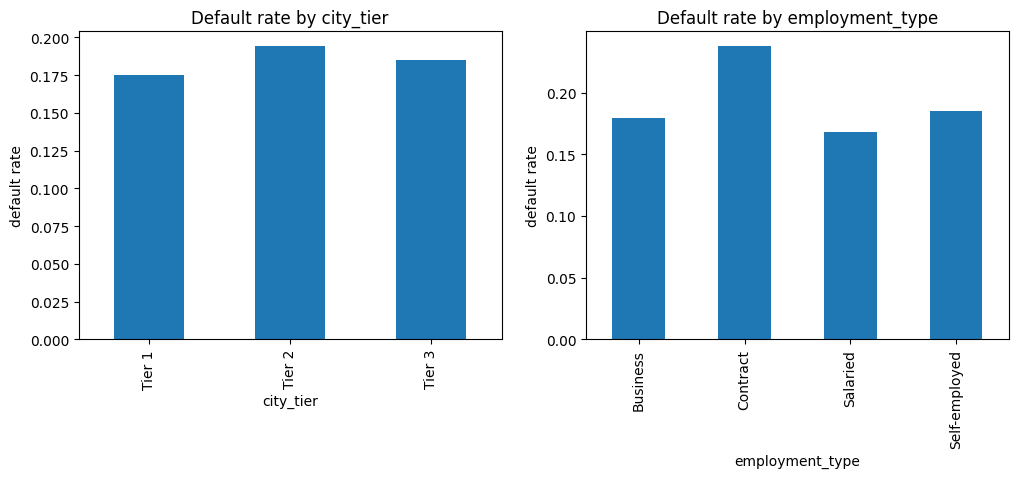

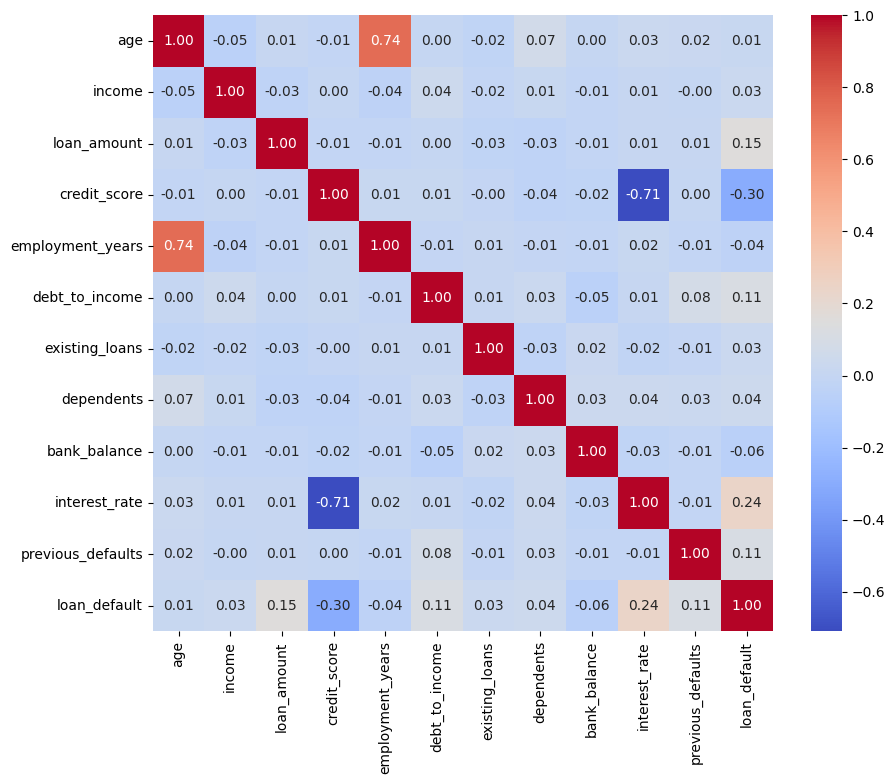

credit_score        -0.298757
bank_balance        -0.055843
employment_years    -0.035513
age                  0.014835
existing_loans       0.026285
income               0.030719
dependents           0.039455
previous_defaults    0.105756
debt_to_income       0.111763
loan_amount          0.153221
interest_rate        0.242694
loan_default         1.000000
Name: loan_default, dtype: float64
city_tier
Tier 1    0.174757
Tier 2    0.194203
Tier 3    0.185185
Name: loan_default, dtype: float64
employment_type
Business         0.179348
Contract         0.237762
Salaried         0.168490
Self-employed    0.185185
Name: loan_default, dtype: float64


In [5]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.boxplot(x='loan_default', y='credit_score', data=df, ax=ax[0])
sns.histplot(data=df, x='credit_score', hue='loan_default', kde=True, ax=ax[1]); plt.show()
fig, ax = plt.subplots(1,2, figsize=(12,4))
for a,col in zip(ax,['city_tier','employment_type']):
    (df.groupby(col)['loan_default'].apply(lambda s:(s=='Yes').mean()).plot(kind='bar', ax=a, title=f'Default rate by {col}')); a.set_ylabel('default rate')
plt.show()
num = df.select_dtypes('number')
plt.figure(figsize=(10,8)); sns.heatmap(num.assign(loan_default=df['loan_default'].map({'Yes':1,'No':0})).corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.show()
print(num.assign(loan_default=df['loan_default'].map({'Yes':1,'No':0})).corr()['loan_default'].sort_values())
print(df.groupby('city_tier')['loan_default'].apply(lambda s:(s=='Yes').mean()))
print(df.groupby('employment_type')['loan_default'].apply(lambda s:(s=='Yes').mean()))

**credit_score** (defaulters have clearly lower scores; correlation about −0.30) and **interest_rate** (defaulters pay higher rates; correlation about +0.24) separate the classes best. loan_amount, debt_to_income and previous_defaults help a little. Default rate barely differs by city_tier (17–19%); Contract workers have a somewhat higher default rate (~24%) than Salaried (~17%).

In [6]:
df = df.drop(columns=['customer_id'])
df['loan_default'] = df['loan_default'].map({'Yes':1,'No':0})
df = pd.get_dummies(df, drop_first=True)
X = df.drop('loan_default', axis=1); y = df['loan_default']
print(X.shape); print(X.columns.tolist())

(1000, 24)
['age', 'income', 'loan_amount', 'credit_score', 'employment_years', 'debt_to_income', 'existing_loans', 'dependents', 'bank_balance', 'interest_rate', 'previous_defaults', 'employment_type_Contract', 'employment_type_Salaried', 'employment_type_Self-employed', 'marital_status_Married', 'marital_status_Single', 'education_High School', 'education_Postgraduate', 'education_Undergraduate', 'loan_purpose_Education', 'loan_purpose_Home', 'loan_purpose_Personal', 'city_tier_Tier 2', 'city_tier_Tier 3']



scikit-learn trees do mathematical comparisons (feature ≤ threshold) and work only on numbers, so text such as “Salaried” or “Tier 2” must first be encoded into numeric columns (one-hot encoding with get_dummies).

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (800, 24) | Test: (200, 24)


The test set simulates new, unseen customers. If we trained on it, the model would just memorise those rows and our score would be over-optimistic; keeping it aside gives an honest estimate of real-world performance.

In [8]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print('Train accuracy:', dt.score(X_train, y_train)); print('Test accuracy :', dt.score(X_test, y_test))

Train accuracy: 1.0
Test accuracy : 0.79


Training accuracy is **1.00** but test accuracy is only **~0.79**. This big gap shows **overfitting**: the fully grown tree memorised the training data, noise included, and does not generalise well.

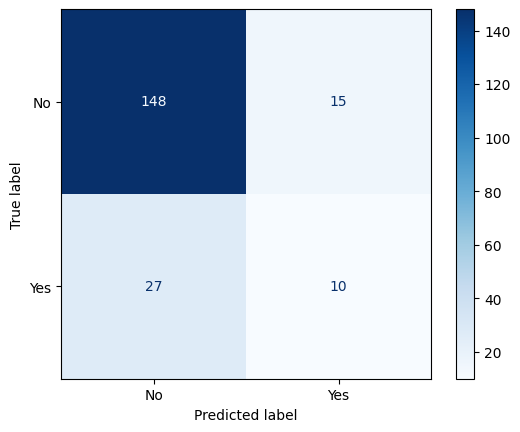

              precision    recall  f1-score   support

           0       0.85      0.91      0.88       163
           1       0.40      0.27      0.32        37

    accuracy                           0.79       200
   macro avg       0.62      0.59      0.60       200
weighted avg       0.76      0.79      0.77       200

ROC-AUC: 0.5891228651964847


In [9]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score, accuracy_score, recall_score, f1_score)
y_pred = dt.predict(X_test)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['No','Yes']).plot(cmap='Blues'); plt.show()
print(classification_report(y_test, y_pred))
print('ROC-AUC:', roc_auc_score(y_test, dt.predict_proba(X_test)[:,1]))

Approving a loan that defaults is worse: the bank loses the principal, whereas rejecting a good customer only loses some interest income. This makes **recall for the “Yes” (default) class** the most important metric (along with ROC-AUC). The untuned tree has recall of only ~0.27 for defaulters and ROC-AUC ~0.59, so it misses most defaulters despite ~79% accuracy.

In [10]:
rows = []
for d in [3,5,7,10]:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    rows.append((d, m.score(X_train,y_train), m.score(X_test,y_test)))
print(pd.DataFrame(rows, columns=['max_depth','train_acc','test_acc']).round(3))
from sklearn.model_selection import GridSearchCV
param_grid = {'max_depth':[3,5,7,10,None], 'min_samples_leaf':[1,5,10,20], 'criterion':['gini','entropy']}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring='roc_auc', n_jobs=-1).fit(X_train, y_train)
print('Best params:', grid.best_params_); print('Best CV ROC-AUC:', round(grid.best_score_,3))
best = grid.best_estimator_
print('Train acc:', best.score(X_train,y_train), '| Test acc:', best.score(X_test,y_test))
print(classification_report(y_test, best.predict(X_test)))
print('Test ROC-AUC:', roc_auc_score(y_test, best.predict_proba(X_test)[:,1]))

   max_depth  train_acc  test_acc
0          3      0.834     0.810
1          5      0.871     0.820
2          7      0.915     0.805
3         10      0.980     0.780
Best params: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 20}
Best CV ROC-AUC: 0.685
Train acc: 0.8475 | Test acc: 0.78
              precision    recall  f1-score   support

           0       0.83      0.92      0.87       163
           1       0.32      0.16      0.21        37

    accuracy                           0.78       200
   macro avg       0.57      0.54      0.54       200
weighted avg       0.73      0.78      0.75       200

Test ROC-AUC: 0.5851434256342232


Among max_depth 3, 5, 7, 10, **max_depth = 5** gave the best test accuracy (~0.82). **not** improve over Step 7, and recall fell. With only 1000 rows and 200 test rows, results are noisy, and the tree itself is a weak model for this data.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)
lr = LogisticRegression(max_iter=1000, random_state=42).fit(scaler.transform(X_train), y_train)
def metrics(name, model, Xt):
    p = model.predict(Xt); pr = model.predict_proba(Xt)[:,1]
    return {'Model':name,'Accuracy':accuracy_score(y_test,p),'Recall':recall_score(y_test,p),'F1':f1_score(y_test,p),'ROC-AUC':roc_auc_score(y_test,pr)}
comp = pd.DataFrame([metrics('Logistic Regression', lr, scaler.transform(X_test)), metrics('Decision Tree (untuned)', dt, X_test), metrics('Decision Tree (tuned)', best, X_test)]).set_index('Model').round(3)
print(comp)

                         Accuracy  Recall     F1  ROC-AUC
Model                                                    
Logistic Regression          0.84   0.243  0.360    0.779
Decision Tree (untuned)      0.79   0.270  0.323    0.589
Decision Tree (tuned)        0.78   0.162  0.214    0.585


 I would recommend **Logistic Regression**. It has the best accuracy (~0.84), the best F1 (~0.36) and by far the best ROC-AUC (~0.78 vs ~0.59 for both trees), so it ranks risky customers much better, and it is simple and easy to explain. Its recall (~0.24) is still low, so in practice the bank should lower the decision threshold to catch more defaulters.

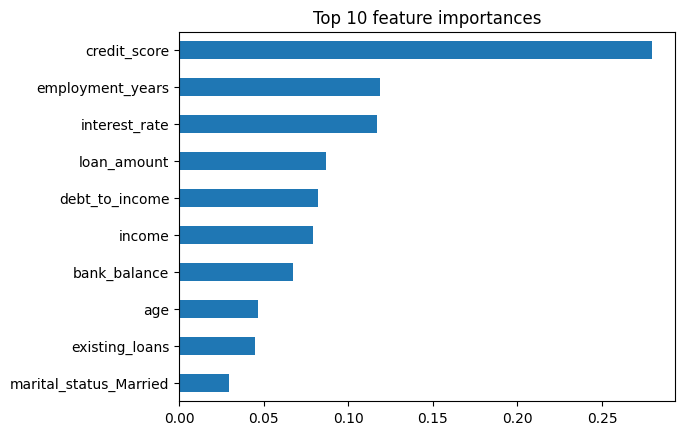

credit_score        0.279356
employment_years    0.118900
interest_rate       0.116777
loan_amount         0.087026
debt_to_income      0.082210
dtype: float64


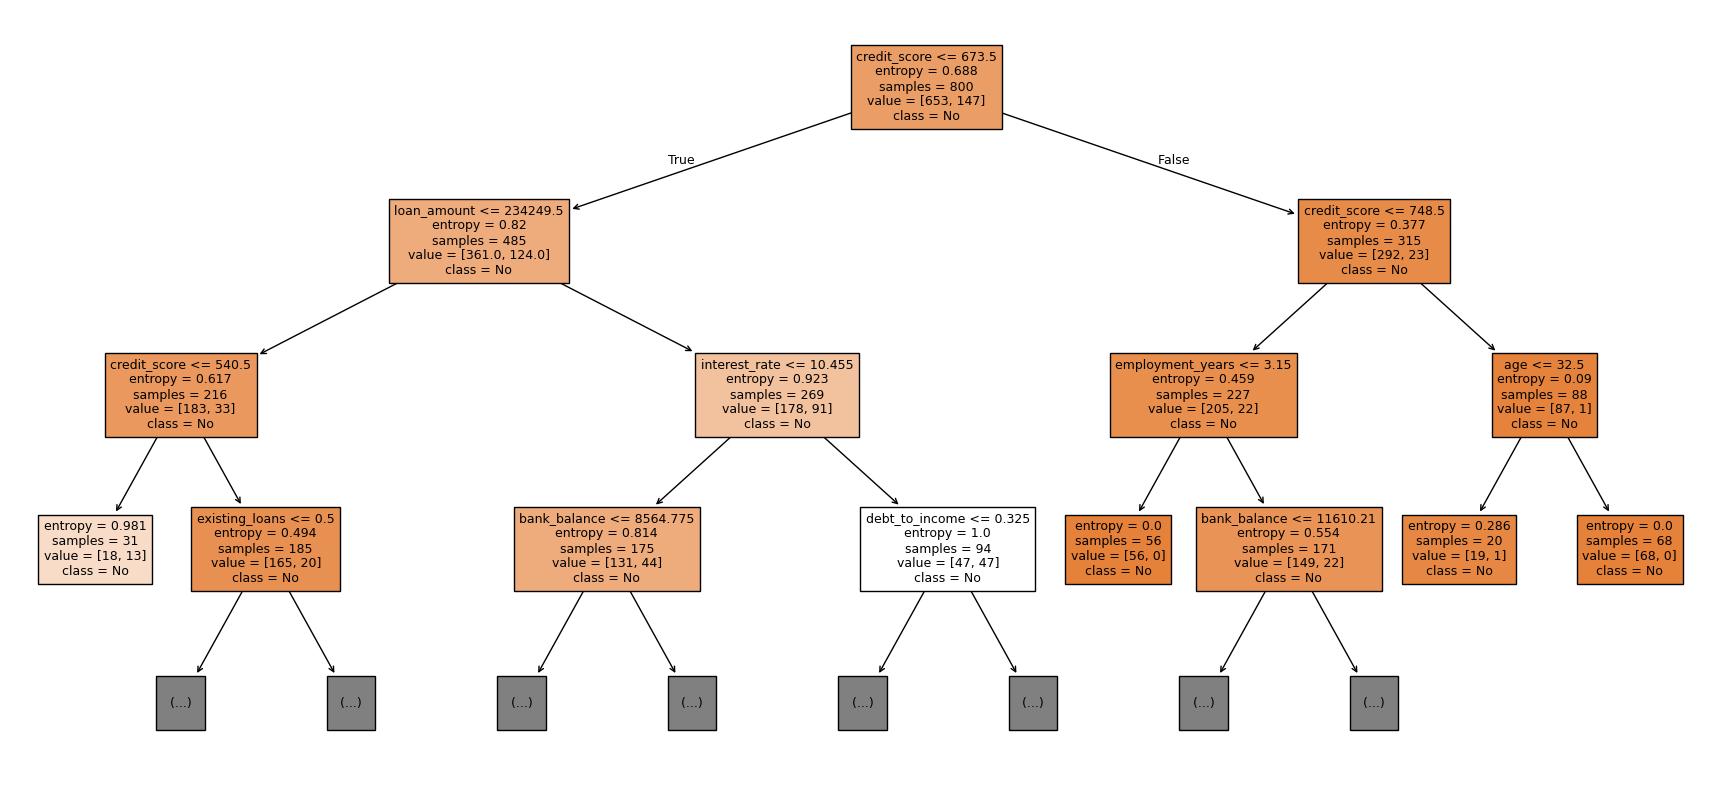

|--- credit_score <= 673.50
|   |--- loan_amount <= 234249.50
|   |   |--- credit_score <= 540.50
|   |   |   |--- class: 0
|   |   |--- credit_score >  540.50
|   |   |   |--- existing_loans <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- existing_loans >  0.50
|   |   |   |   |--- truncated branch of depth 4
|   |--- loan_amount >  234249.50
|   |   |--- interest_rate <= 10.45
|   |   |   |--- bank_balance <= 8564.78
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- bank_balance >  8564.78
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- interest_rate >  10.45
|   |   |   |--- debt_to_income <= 0.33
|   |   |   |   |--- class: 0
|   |   |   |--- debt_to_income >  0.33
|   |   |   |   |--- truncated branch of depth 2
|--- credit_score >  673.50
|   |--- credit_score <= 748.50
|   |   |--- employment_years <= 3.15
|   |   |   |--- class: 0
|   |   |--- employment_years >  3.15
|   |   |   |--- bank_balance <= 11610.21
|   |   |   |

In [12]:
pd.Series(best.feature_importances_, index=X.columns).nlargest(10).sort_values().plot(kind='barh', title='Top 10 feature importances'); plt.show()
print(pd.Series(best.feature_importances_, index=X.columns).nlargest(5))
plt.figure(figsize=(22,10)); plot_tree = __import__('sklearn.tree',fromlist=['plot_tree']).plot_tree
plot_tree(best, max_depth=3, feature_names=X.columns, class_names=['No','Yes'], filled=True, fontsize=9); plt.show()
from sklearn.tree import export_text
print(export_text(best, feature_names=list(X.columns), max_depth=3))

Top five features: **credit_score, employment_years, interest_rate, loan_amount, debt_to_income**. credit_score and interest_rate match Step 4; loan_amount and debt_to_income were weaker but positive in the correlation map. employment_years did not stand out in Step 4, so the tree may be using it for noise. Two rules in plain English: (1) *If credit_score > 748, the tree predicts the customer will not default* (very high scores are safe). (2) *If credit_score ≤ 673 and loan_amount > 234,000 and the interest rate > 10.45% and debt-to-income ≤ 0.33, the customer is predicted not to default; with debt-to-income above 0.33 the tree goes deeper to decide* — i.e., low credit score plus a large, expensive loan and heavy debt is the risky zone. *(Check the printed tree rules in your own run and quote two that you can see.)*

We built and tested models that predict loan default using 1000 cleaned customer records. A decision tree fitted without limits memorised the training data and performed poorly on new customers.. (~90% recall for non-defaulters). **Limitations:** it catches only about a quarter of true defaulters, because only 18% of the data are defaults and the dataset is small. **Improvement:** collect more data and use class weighting / a lower decision threshold (or a Random Forest) to raise recall on defaulters.

In [13]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_train, y_train)
print(pd.concat([comp, pd.DataFrame([metrics('Random Forest', rf, X_test)]).set_index('Model').round(3)]))

                         Accuracy  Recall     F1  ROC-AUC
Model                                                    
Logistic Regression         0.840   0.243  0.360    0.779
Decision Tree (untuned)     0.790   0.270  0.323    0.589
Decision Tree (tuned)       0.780   0.162  0.214    0.585
Random Forest               0.825   0.108  0.186    0.727


In [14]:
#A Random Forest (ROC-AUC ~0.73, accuracy ~0.83) beats the tuned tree (ROC-AUC ~0.59) because averaging many trees reduces overfitting, but its recall for defaulters (~0.11) is still low and Logistic Regression remains best here.